In [2]:
from Bio import SeqIO
import pandas as pd
from Bio import SearchIO
import numpy as np
import os

In [3]:
print(os.listdir("outputs"))

['nucleotide_composition_stats.csv', 'pairwise_folsomia_alignments_intron', 'impatiens_v_coprophila_reciprocal_best_blast_results.csv', 'sciarid_species_tree', 'SI_tables', 'GCA_965233685.1_liftoff', 'sra_accessions.tsv', 'bradysia_endosymbiont_blast_top_hits.csv', 'hgt_go_terms.csv', '.ipynb_checkpoints', 'genomic_clusters.csv', 'read_depth_per_gene.csv', 'PROKKA_06122024', 'tryptophan_kynurenine.tsv', 'salivary_upregulated_hgts.tsv', 'deeploc_results.csv', 'pairwise_dnds.csv', 'biological_process_enrichment.tsv', 'larvae_non_larvae_meta.csv', 'diptera_wide_screen', 'deseq2larval.csv', 'SI_inspection_bradysia_6_23_2026.tsv', 'dna_repair.tsv', 'pairwise_copro_impatiens_dnds', 'bimpatiens_v_coprophila_reciprocal_best_blast_results.csv', 'final_concatenated_arthropod_order.nwk', 'lingenua_v_coprophila_reciprocal_best_blast_results.csv', 'final_concatenated_arthropod_order_collapsed_diptera.nwk', 'biosynthesis.tsv', 'molecular_function_enrichment.tsv', 'htgs_mean_sex_stage_tpms.tsv', 'con

In [2]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")


from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 300
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype']='none'
import multiprocessing as mp

### Perform percent identity comparison of dipteran and hgt genes to collembolan top hit

In [3]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")

In [4]:
##get blast statistics for top collembolan hit 
def get_identity_collembola(x):
    df = pd.read_csv(
        f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/{x}.tsv",
        sep="\t",
        nrows=2000
    )

    df=df[df.slineage.astype(str).str.contains('Collembola')]
    
    if df.shape[0]>0:
      
        return list(df.iloc[0,:].loc[["sscinames","sseqid","pident","qcovhsp","evalue"]].values)
    else:
        return [np.nan,np.nan,np.nan,np.nan, np.nan]


In [5]:
td=list(dfriso[~dfriso['type'].isin(["orphan","none"])].index)
with mp.Pool(59) as p:
    results = p.map(get_identity_collembola, td)
dfriso.loc[td,["Collembola scinames","Collembola sseqid","Collembola percent identity","Collembola Coverage", "Collembola evalue"]]=results

In [6]:
dftree=pd.read_csv("outputs/SI_inspection_bradysia_6_23_2026.tsv",sep="\t",index_col=0)
dftree=dftree[dftree.annotation.isin(["One step","Two step"])&(dftree['primary neighbor']=="Collembola")]

In [7]:
## collect tree-confirmed collembolan origin hgts
confirmed_collembola=set()
import ast
for index, row in dftree.iterrows():
    confirmed_collembola=confirmed_collembola|set(ast.literal_eval(row.cluster_seqs))
for index, row in dfriso.iterrows():
    if index in confirmed_collembola:
        dfriso.loc[index,'Tree_collembola']=True
dfriso['Tree_collembola']=dfriso.Tree_collembola.fillna(False)


/tmp/ipykernel_1387971/2506410430.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfriso['Tree_collembola']=dfriso.Tree_collembola.fillna(False)


In [8]:
dfcollembola=dfriso.loc[:,['type','Collembola scinames', 'Collembola sseqid',
       'Collembola percent identity', 'Collembola Coverage',
       'Collembola evalue', 'Tree_collembola']]

In [9]:
for index, row in dfcollembola.iterrows():
    if row.Tree_collembola:
        dfcollembola.loc[index,'type']='HTG' 


In [10]:
dfcollembola=dfcollembola[~dfcollembola.type.isin(['alien','non_dipt'])]

In [11]:
dfcollembola=dfcollembola[dfcollembola["Collembola scinames"].astype(str)!='nan']

/n/home11/rkapoor/.conda/envs/rishabh/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


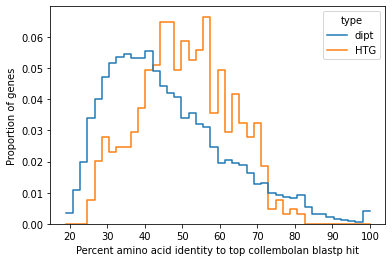

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a new figure and axis
plt.figure()


sns.histplot(
    data=dfcollembola,
    x="Collembola percent identity",
    hue='type',
    stat='proportion',
    element='step',
    common_bins=True,
    common_norm=False,
    fill=False
   
)

# Add legend to the plot

plt.xlabel('Percent amino acid identity to top collembolan blastp hit')
plt.ylabel('Proportion of genes')


plt.savefig('figures/collembolan_tree_confirmed_percent_identity_plot.svg',format='svg',bbox_inches='tight')

In [13]:
from scipy.stats import mannwhitneyu


# Perform Mann-Whitney U test
statistic, p_value = mannwhitneyu(dfcollembola[dfcollembola['type']=='HTG']['Collembola percent identity'], dfcollembola[dfcollembola['type']=='dipt']['Collembola percent identity'], alternative='greater')

print("Mann-Whitney U test statistic:", statistic)
print("P-value:", p_value)
print(np.median(dfcollembola[dfcollembola['type']=='dipt']['Collembola percent identity']),np.median(dfcollembola[dfcollembola['type']=='HTG']['Collembola percent identity']))


Mann-Whitney U test statistic: 3889623.5
P-value: 4.903402507552476e-26
43.0 50.8


In [14]:
dfcollembola.to_csv("outputs/collembola_pident_comparison.csv")

In [3]:
import pandas as pd
from collections import Counter
dfcollembola=pd.read_csv("outputs/collembola_pident_comparison.csv",index_col=0)
Counter(dfcollembola['type'])

Counter({'dipt': 9664, 'HTG': 646})

## Intron conservation analysis
Looks for evidence of conserved intron position in F. candida for two-step transfers 

In [18]:
%%bash
##download f. candida genome
curl -OJX GET \
"https://api.ncbi.nlm.nih.gov/datasets/v2alpha/genome/accession/GCF_002217175.1/download?include_annotation_type=GENOME_GFF&include_annotation_type=PROT_FASTA&include_annotation_type=GENOME_FASTA&include_annotation_type=CDS_FASTA&hydrated=FULLY_HYDRATED"

unzip -o ncbi_dataset.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0Warning: Failed to create the file ncbi_dataset.zip: File exists
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
curl: (23) Failed writing header


Archive:  ncbi_dataset.zip
  inflating: README.md               
  inflating: ncbi_dataset/data/assembly_data_report.jsonl  
  inflating: ncbi_dataset/data/GCF_002217175.1/cds_from_genomic.fna  
  inflating: ncbi_dataset/data/GCF_002217175.1/genomic.gff  
  inflating: ncbi_dataset/data/GCF_002217175.1/protein.faa  
  inflating: ncbi_dataset/data/dataset_catalog.json  
  inflating: md5sum.txt              


In [4]:
## load input files for Folsomia candida 
gff=pd.read_csv("ncbi_dataset/data/GCF_002217175.1/genomic.gff",sep="\t",comment="#",header=None)
input_file = open(f"ncbi_dataset/data/GCF_002217175.1/protein.faa")
fastap = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

input_file = open(f"ncbi_dataset/data/GCF_002217175.1/cds_from_genomic.fna")
fastac = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [5]:
## load input files for Bradysia coprophila
gff2=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t",comment="#",header=None)
input_file = open(f"ncbi_dataset/data/GCF_014529535.2/protein.faa")
fastap2 = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
input_file = open(f"ncbi_dataset/data/GCF_014529535.2/GCF_014529535.2_BU_Bcop_v2.1_cds_from_genomic.fna")
fastac2 = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [6]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col="accession")

In [7]:
dfrmerged=pd.read_csv("outputs/SI_inspection_bradysia_6_23_2026.tsv",sep="\t",index_col=0)

In [40]:
## collect tree-confirmed collembolan-bacteria origin two-step hgts
two_step_collembola=set()
import ast
for index, row in dfrmerged[(dfrmerged.annotation.isin(['Two step', 'Two step unclear direction']))&(dfrmerged['primary neighbor']=='Collembola')&(dfrmerged['secondary neighbor']=='Bacteria')].iterrows():
    two_step_collembola=two_step_collembola|set(ast.literal_eval(row.cluster_seqs))


In [41]:
##make a dataframe with two_step_collembola and their top collembolan hit info 
dfi=dfriso[dfriso.index.isin(two_step_collembola)]
td=list(dfi.index)
with mp.Pool(59) as p:
    results = p.map(get_identity_collembola, td)
dfi.loc[td,["Collembola scinames","Collembola sseqid","Collembola percent identity","Collembola Coverage", "Collembola evalue"]]=results

In [42]:
##limit to those with Folsomia candida as the top collembolan hit hit
dfi=dfi[dfi['Collembola scinames'].str.contains('Folsomia candida')]

In [43]:
## replace genbank with refseq if available
for index, row in dfi[~dfi['Collembola sseqid'].str.contains('XP_')].iterrows():
    df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/{index}.tsv",sep="\t",nrows=2000)
    try:
        sseqid=df[(df.sseqid.astype(str).str.contains('XP_'))&(df.sscinames.astype(str).str.contains('Folsomia candida'))].iloc[0,:]['sseqid']
        dfi.loc[index,'Collembola sseqid']=sseqid

    except:
        dfi.loc[index,'Collembola sseqid']='missing'
    
dfi=dfi[dfi['Collembola sseqid']!='missing']    
  

In [44]:
## add annotation type
for index, row in dfi.iterrows():
    dfi.loc[index,'Annotation']=dfrmerged[dfrmerged.cluster_seqs.str.contains(index)].annotation.values

In [1]:
from pathlib import Path
from Bio import SeqIO
### Written by RK with re-formatting by chatgpt

############################################################
# Pretty-print alignment with lowercase exon-end markers
############################################################

def print_alignment_with_boundaries(
        L1, L2, sp_name, qp_name, outdir, width=80):
    """
    Pretty-print the codon alignment.
    Lowercase bases = exon-end positions.
    A caret (^) is printed under positions where BOTH species are lowercase.
    Output is written to alignment_with_exon_boundaries.txt in outdir.
    """

    seq1 = "".join(L1)
    seq2 = "".join(L2)

    # Prefix labels
    label1 = f"folsomia_{sp_name}"
    label2 = f"bradysia_{qp_name}"

    # Dynamic padding based on longest label
    pad = max(len(label1), len(label2)) + 2

    outfile = outdir / "alignment_with_exon_boundaries.txt"
    with outfile.open("w") as f:

        header = (
            "=== Alignment with exon-end markers (lowercase) ===\n"
            f"Seq1 = {label1}\n"
            f"Seq2 = {label2}\n"
            f"(Displaying {width} columns per block)\n\n"
        )
        f.write(header)
        print(header, end="")

        for i in range(0, len(seq1), width):
            b1 = seq1[i:i+width]
            b2 = seq2[i:i+width]

            # Mark shared-lowercase positions
            mark = []
            for a, b in zip(b1, b2):
                if a.islower() and b.islower():
                    mark.append("^")
                elif a.islower() or b.islower():
                    mark.append("*")
                else:
                    mark.append(" ")
            mark = "".join(mark)

            line1 = f"{label1.ljust(pad)}{b1}"
            line2 = f"{label2.ljust(pad)}{b2}"
            line3 = f"{' '.ljust(pad)}{mark}"

            # Write to file
            f.write(line1 + "\n")
            f.write(line2 + "\n")
            f.write(line3 + "\n\n")


############################################################
# Helper: extract cds ID from GFF attributes (ID=cds-...)
############################################################

def get_cds_id_from_attr(attr_string):
    """
    Given a GFF attributes string, extract the cds ID from a field
    like 'ID=cds-XYZ123'.
    Returns just the suffix after 'ID=cds-'.
    """
    for field in attr_string.split(";"):
        field = field.strip()
        if field.startswith("ID=cds-"):
            return field[len("ID=cds-"):]
    raise ValueError(f"No 'ID=cds-' field found in attributes: {attr_string}")


############################################################
# Get exon/CDS ends from GFF using ID=cds-*
############################################################

def exon_end_positions_from_gff_cds_id(cds_id, gff_df, feature_type="CDS"):
    """
    Extract exon/CDS boundaries for a given cds_id using GFF entries
    whose attributes contain 'ID=cds-<cds_id>' and type == feature_type
    (typically 'CDS').

    Returns a list of exon-end positions in CDS coordinate space (0-based).
    """
    mask_id = gff_df[8].str.contains(f"ID=cds-{cds_id}", na=False)
    cds_rows = gff_df[mask_id & (gff_df[2] == feature_type)].copy()

    if cds_rows.empty:
        raise ValueError(f"No {feature_type} features found for ID=cds-{cds_id}")

    # Determine strand
    strand = cds_rows.iloc[0][6]

    # Sort CDS fragments in transcription order
    if strand == "+":
        cds_rows = cds_rows.sort_values(by=3)  # start ascending
    else:
        cds_rows = cds_rows.sort_values(by=3, ascending=False)

    # Compute lengths of each CDS fragment
    lengths = (cds_rows[4] - cds_rows[3] + 1).tolist()

    # Compute exon ends in CDS coordinates (0-based)
    exon_ends = []
    pos = 0
    for L in lengths:
        exon_ends.append(pos + L - 1)  # last base of exon
        pos += L

    return exon_ends


############################################################
# FASTA writing (pairwise protein + CDS)
############################################################

def write_pairwise_fastas(qp, sp, qp_cds_id, sp_cds_id, outdir):
    """
    Write pairwise protein and CDS FASTA files for qp and sp.
    Uses cds IDs to find CDS sequences in fastac2 / fastac.
    """
    prot_file = outdir / "prot.fasta"
    cds_file  = outdir / "cds.fasta"

    # Proteins
    with prot_file.open("w") as f:
        f.write(f">{qp}\n{fastap2[qp].seq}\n")
        f.write(f">{sp}\n{fastap[sp].seq}\n")

    # CDS sequences: find using cds_id substring in the keys
    qp_cds_key = [k for k in fastac2.keys() if qp_cds_id in k][0]
    sp_cds_key = [k for k in fastac.keys()  if sp_cds_id in k][0]

    with cds_file.open("w") as f:
        f.write(f">{qp}\n{fastac2[qp_cds_key].seq}\n")
        f.write(f">{sp}\n{fastac[sp_cds_key].seq}\n")


############################################################
# MUSCLE + pal2nal codon alignment
############################################################

def make_codon_alignment(outdir, qp, sp):
    """
    Run MUSCLE on protein FASTA, reorder sequences, then run pal2nal
    to produce a codon alignment.
    """
    prot     = outdir / "prot.fasta"
    ali_prot = outdir / "ali_prot.fasta"
    cds      = outdir / "cds.fasta"
    codonali = outdir / "codon_ali.fasta"

    # MUSCLE (protein alignment)
    !singularity exec /cvmfs/singularity.galaxyproject.org/m/u/muscle:5.1--h9f5acd7_2 \
        muscle -align {prot} -output {ali_prot}

    # Reorder aligned sequences to have qp first, sp second
    aa = SeqIO.to_dict(SeqIO.parse(ali_prot.open(), "fasta"))
    with ali_prot.open("w") as f:
        f.write(f">{qp}\n{aa[qp].seq}\n")
        f.write(f">{sp}\n{aa[sp].seq}\n")

    # PAL2NAL (codon alignment)
    !singularity exec /cvmfs/singularity.galaxyproject.org/p/a/pal2nal:14.1--pl5321hdfd78af_3 \
        pal2nal.pl {ali_prot} {cds} -output fasta > {codonali}


############################################################
# Map CDS positions to alignment positions
############################################################

def map_cds_to_alignment(seq):
    """
    Build a dict mapping CDS index (0-based, ungapped) -> alignment index.
    """
    imap = {}
    cds_pos = 0
    for aln_pos, base in enumerate(seq):
        imap[cds_pos] = aln_pos
        if base != "-":
            cds_pos += 1
    return imap


def mark_boundaries_from_gff(outdir, sp, qp, sp_exon_ends, qp_exon_ends):
    """
    Read codon alignment, project exon-end positions from CDS coords
    onto alignment coords, and mark them as lowercase bases.

    - All non-gap characters are uppercased by default.
    - Exon-end positions are turned to lowercase.
    """
    codonali = outdir / "codon_ali.fasta"
    fdict = SeqIO.to_dict(SeqIO.parse(codonali.open(), "fasta"))

    # Original sequences from alignment
    seq1 = str(fdict[sp].seq)
    seq2 = str(fdict[qp].seq)

    # Start with all uppercase (except gaps, which stay '-')
    l1 = [c.upper() if c != "-" else "-" for c in seq1]
    l2 = [c.upper() if c != "-" else "-" for c in seq2]

    # Map CDS positions to alignment positions using the original sequences
    im1 = map_cds_to_alignment(seq1)
    im2 = map_cds_to_alignment(seq2)

    # Mark exon ends by lowercasing the nucleotide at that alignment position
    for end in sp_exon_ends:
        if end in im1:
            pos = im1[end]
            if l1[pos] != "-":
                l1[pos] = l1[pos].lower()

    for end in qp_exon_ends:
        if end in im2:
            pos = im2[end]
            if l2[pos] != "-":
                l2[pos] = l2[pos].lower()

    return l1, l2


############################################################
# Overlap statistics (using lowercase as boundary markers)
############################################################

def intron_overlap_stats(L1, L2):
    """
    Given two aligned sequences where lowercase bases mark exon ends,
    compute overlap statistics:

    - n_union: columns where at least one species has a lowercase base
    - n_int:   columns where both species have lowercase bases
    - n_fols:  columns where Folsomia (L1) has lowercase
    - n_brad:  columns where Bradysia (L2) has lowercase
    """
    n_union = n_int = n_fols = n_brad = 0
    for a, b in zip(L1, L2):
        a_is = a.islower()
        b_is = b.islower()
        if a_is or b_is:
            n_union += 1
        if a_is and b_is:
            n_int += 1
        if a_is:
            n_fols += 1
        if b_is:
            n_brad += 1
    return n_int, n_union, n_fols, n_brad


############################################################
# MAIN FUNCTION: GFF-based exon ends using ID=cds-
############################################################

def get_intron_conservation_hgt(qp,sp):
    """
    For a given query protein index `ind` (qp) and its top Collembola hit (sp),
    compute conservation of annotated intron positions using:

      - GFF CDS features with ID=cds-*
      - MUSCLE + pal2nal codon alignment

    Exon ends are marked by making that nucleotide lowercase in the alignment.
    The function prints the alignment with shared lowercase positions marked
    by '^' and returns:

        n_int, n_union, n_fols, n_brad
    """
 

    outdir = Path("pairwise_folsomia_alignments_intron") / str(qp)
    outdir.mkdir(parents=True, exist_ok=True)

    # 1. Find attribute lines for qp and sp in their respective GFFs
    sp_attr_row = gff[gff[8].str.contains(sp, na=False)].iloc[0]
    qp_attr_row = gff2[gff2[8].str.contains(qp, na=False)].iloc[0]

    sp_attr = sp_attr_row[8]
    qp_attr = qp_attr_row[8]

    # 2. Extract cds IDs from 'ID=cds-...'
    sp_cds_id = get_cds_id_from_attr(sp_attr)
    qp_cds_id = get_cds_id_from_attr(qp_attr)

    # 3. Write pairwise FASTAs (proteins + CDS)
    write_pairwise_fastas(qp, sp, qp_cds_id, sp_cds_id, outdir)

    # 4. Build codon alignment
    make_codon_alignment(outdir, qp, sp)

    # 5. Get exon-end positions in CDS coordinates from GFF
    sp_exon_ends = exon_end_positions_from_gff_cds_id(sp_cds_id, gff,  feature_type="CDS")
    qp_exon_ends = exon_end_positions_from_gff_cds_id(qp_cds_id, gff2, feature_type="CDS")

    # 6. Mark exon boundaries on alignment as lowercase
    L1, L2 = mark_boundaries_from_gff(outdir, sp, qp, sp_exon_ends, qp_exon_ends)

    # 7. Print alignment for visual inspection
    print_alignment_with_boundaries(L1, L2, sp, qp, outdir)

    # 8. Return summary stats
    return intron_overlap_stats(L1, L2)


In [47]:
!mkdir -p pairwise_folsomia_alignments_intron
for index, row in dfi.iterrows():
    dfi.loc[index,["n_int", "n_union", "n_fols", "n_brad"]]=get_intron_conservation_hgt(index,row['Collembola sseqid'] )


muscle 5.1.linux64 []  1056Gb RAM, 112 cores
Built May 13 2023 06:17:56
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 2 seqs, avg length 310, max 340

00:00 7.7Mb  CPU has 112 cores, defaulting to 20 threads


00:00 7.7Mb   100.0% Calc posteriors
00:00 7.7Mb   100.0% UPGMA5         
=== Alignment with exon-end markers (lowercase) ===
Seq1 = folsomia_XP_021965199.1
Seq2 = bradysia_XP_037024379.1
(Displaying 80 columns per block)


muscle 5.1.linux64 []  1056Gb RAM, 112 cores
Built May 13 2023 06:17:56
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 2 seqs, avg length 246, max 249

00:00 7.7Mb  CPU has 112 cores, defaulting to 20 threads


00:00 7.7Mb   100.0% Calc posteriors
00:00 7.7Mb   100.0% UPGMA5         
=== Alignment with exon-end markers (lowercase) ===
Seq1 = folsomia_XP_021961872.1
Seq2 = bradysia_XP_037025070.1
(Displaying 80 columns per block)


muscle 5.1.linux64 []  1056Gb RAM, 112 cores
Built May 13 2023 06:17:56
(C) Copyright 2

In [48]:
## total number of analyzed genes
dfi.shape[0]

34

In [49]:
## total number of genes in which there is at least one conserved intron position
dfi[dfi.n_int>0].shape[0]

15

In [50]:
dfi=dfi.sort_values('n_int')

In [53]:
dfi.loc[:,['Collembola sseqid','Annotation',"n_int", "n_union", "n_fols", "n_brad"]].to_csv("outputs/folsomia_conserved_introns.csv")

In [54]:
#### N-(5-amino-5-carboxypentanoyl)-L-cysteinyl-D-valine synthase
df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/XP_037037668.1.tsv",sep="\t",nrows=2000)
df[df.sscinames.astype(str).str.contains("Folsomia")]

,Unnamed: 0,qseqid,sseqid,stitle,staxids,sscinames,sphylums,skingdoms,slineage,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore,qcovhsp
3,3,XP_037037668.1,OXA60265.1,OXA60265.1 N-(5-amino-5-carboxypentanoyl)-L-cy...,158441,Folsomia candida,Arthropoda,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,46.1,3790,1803,84,1,3660,1,3685,0.0,3019,100.0
94,94,XP_037037668.1,OXA38152.1,OXA38152.1 N-(5-amino-5-carboxypentanoyl)-L-cy...,158441,Folsomia candida,Arthropoda,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,45.6,2584,1067,53,1,2525,1,2314,0.0,2028,69.0
104,104,XP_037037668.1,XP_021966806.2,XP_021966806.2 LOW QUALITY PROTEIN: N-(5-amino...,158441,Folsomia candida,Arthropoda,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,51.9,1953,840,37,1,1899,1,1908,0.0,1835,51.9


In [9]:
## OXA60265.1 is 100% identical to refseq XP_035703636.1 

In [8]:
get_intron_conservation_hgt("XP_037037668.1","XP_021966806.2") 


muscle 5.1.linux64 []  1056Gb RAM, 112 cores
Built May 13 2023 06:17:56
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 2 seqs, avg length 2790, max 3660

00:00 7.7Mb  CPU has 112 cores, defaulting to 20 threads


00:00 7.7Mb   100.0% Calc posteriors
00:01 7.7Mb   100.0% UPGMA5         
=== Alignment with exon-end markers (lowercase) ===
Seq1 = folsomia_XP_021966806.2
Seq2 = bradysia_XP_037037668.1
(Displaying 80 columns per block)



(1, 3, 1, 3)

In [56]:
### isopenicillin n-synthase
df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/XP_037040229.1.tsv",sep="\t",nrows=2000)
df[df.sscinames.astype(str).str.contains("Folsomia")]

,Unnamed: 0,qseqid,sseqid,stitle,staxids,sscinames,sphylums,skingdoms,slineage,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore,qcovhsp
2,2,XP_037040229.1,XP_021945242.1,XP_021945242.1 isopenicillin N synthase [Folso...,158441,Folsomia candida,Arthropoda,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,73.0,326,85,2,5,327,8,333,2.660000e-175,499.0,98.8
69,69,XP_037040229.1,BAP16522.1,"BAP16522.1 isopenicillin N synthase, partial [...",158441,Folsomia candida,Arthropoda,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,76.2,206,48,1,58,262,1,206,4.720000e-115,341.0,62.7
992,992,XP_037040229.1,XP_021967052.1,XP_021967052.1 probable iron/ascorbate oxidore...,158441,Folsomia candida,Arthropoda,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,28.8,330,202,13,4,315,6,320,4.040000e-23,108.0,95.4


In [57]:
get_intron_conservation_hgt("XP_037040229.1","XP_021945242.1")



muscle 5.1.linux64 []  1056Gb RAM, 112 cores
Built May 13 2023 06:17:56
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 2 seqs, avg length 330, max 333

00:00 7.7Mb  CPU has 112 cores, defaulting to 20 threads


00:00 7.7Mb   100.0% Calc posteriors
00:00 7.7Mb   100.0% UPGMA5         
=== Alignment with exon-end markers (lowercase) ===
Seq1 = folsomia_XP_021945242.1
Seq2 = bradysia_XP_037040229.1
(Displaying 80 columns per block)



(3, 4, 3, 4)

In [58]:
### isocitrate lyase
df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/XP_037048622.1.tsv",sep="\t",nrows=2000)
df[df.sscinames.astype(str).str.contains("Folsomia")]


,Unnamed: 0,qseqid,sseqid,stitle,staxids,sscinames,sphylums,skingdoms,slineage,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore,qcovhsp
52,52,XP_037048622.1,XP_021962860.1,XP_021962860.1 isocitrate lyase [Folsomia cand...,158441,Folsomia candida,Arthropoda,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,65.2,485,147,4,1,468,1,480,1.400000e-217,618,100.0


In [60]:
### isocitrate lyase
get_intron_conservation_hgt('XP_037048622.1',"XP_021962860.1")


muscle 5.1.linux64 []  1056Gb RAM, 112 cores
Built May 13 2023 06:17:56
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 2 seqs, avg length 476, max 483

00:00 7.7Mb  CPU has 112 cores, defaulting to 20 threads


00:00 7.7Mb   100.0% Calc posteriors
00:00 7.7Mb   100.0% UPGMA5         
=== Alignment with exon-end markers (lowercase) ===
Seq1 = folsomia_XP_021962860.1
Seq2 = bradysia_XP_037048622.1
(Displaying 80 columns per block)



(0, 7, 3, 4)

In [62]:
### malate synthase
df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/XP_037048618.1.tsv",sep="\t",nrows=2000)
df[df.sscinames.astype(str).str.contains("Folsomia")]

,Unnamed: 0,qseqid,sseqid,stitle,staxids,sscinames,sphylums,skingdoms,slineage,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore,qcovhsp
44,44,XP_037048618.1,XP_021962959.1,XP_021962959.1 malate synthase [Folsomia candida],158441,Folsomia candida,Arthropoda,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,66.4,530,162,9,40,556,88,614,9.740000e-237,675,93.0


In [63]:
get_intron_conservation_hgt("XP_037048618.1","XP_021962959.1")


muscle 5.1.linux64 []  1056Gb RAM, 112 cores
Built May 13 2023 06:17:56
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 2 seqs, avg length 585, max 614

00:00 7.7Mb  CPU has 112 cores, defaulting to 20 threads


00:00 7.7Mb   100.0% Calc posteriors
00:00 7.7Mb   100.0% UPGMA5         
=== Alignment with exon-end markers (lowercase) ===
Seq1 = folsomia_XP_021962959.1
Seq2 = bradysia_XP_037048618.1
(Displaying 80 columns per block)



(1, 14, 6, 9)

In [73]:
!rm  ncbi_dataset.zip

In [74]:
%%bash
##download Paramacrobiotus metropolitanus  genome
curl -OJX GET \
"https://api.ncbi.nlm.nih.gov/datasets/v2alpha/genome/accession/GCF_019649055.1/download?include_annotation_type=GENOME_GFF&include_annotation_type=PROT_FASTA&include_annotation_type=GENOME_FASTA&include_annotation_type=CDS_FASTA&hydrated=FULLY_HYDRATED"

unzip -o ncbi_dataset.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 76.0M    0 76.0M    0     0  54.6M      0 --:--:--  0:00:01 --:--:-- 54.6M


Archive:  ncbi_dataset.zip
  inflating: README.md               
  inflating: ncbi_dataset/data/assembly_data_report.jsonl  
  inflating: ncbi_dataset/data/GCF_019649055.1/cds_from_genomic.fna  
  inflating: ncbi_dataset/data/GCF_019649055.1/GCF_019649055.1_Prichtersi_v1.0_genomic.fna  
  inflating: ncbi_dataset/data/GCF_019649055.1/genomic.gff  
  inflating: ncbi_dataset/data/GCF_019649055.1/protein.faa  
  inflating: ncbi_dataset/data/dataset_catalog.json  
  inflating: md5sum.txt              


In [75]:
## load input files for Paramacrobiotus metropolitanus 
gff=pd.read_csv("ncbi_dataset/data/GCF_019649055.1/genomic.gff",sep="\t",comment="#",header=None)
input_file = open(f"ncbi_dataset/data/GCF_019649055.1/protein.faa")
fastap = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))
input_file = open(f"ncbi_dataset/data/GCF_019649055.1/cds_from_genomic.fna")
fastac = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [76]:
!mkdir "pairwise_paramacrobiotus_alignments_intron"

In [77]:
from pathlib import Path
from Bio import SeqIO


############################################################
# Pretty-print alignment with lowercase exon-end markers
############################################################

def print_alignment_with_boundaries(
        L1, L2, sp_name, qp_name, outdir, width=80):
    """
    Pretty-print the codon alignment.
    Lowercase bases = exon-end positions.
    A caret (^) is printed under positions where BOTH species are lowercase.
    Output is written to alignment_with_exon_boundaries.txt in outdir.
    """

    seq1 = "".join(L1)
    seq2 = "".join(L2)

    # Prefix labels
    label1 = f"paramacrobiotus_{sp_name}"
    label2 = f"bradysia_{qp_name}"

    # Dynamic padding based on longest label
    pad = max(len(label1), len(label2)) + 2

    outfile = outdir / "alignment_with_exon_boundaries.txt"
    with outfile.open("w") as f:

        header = (
            "=== Alignment with exon-end markers (lowercase) ===\n"
            f"Seq1 = {label1}\n"
            f"Seq2 = {label2}\n"
            f"(Displaying {width} columns per block)\n\n"
        )
        f.write(header)
        print(header, end="")

        for i in range(0, len(seq1), width):
            b1 = seq1[i:i+width]
            b2 = seq2[i:i+width]

            # Mark shared-lowercase positions
            mark = []
            for a, b in zip(b1, b2):
                if a.islower() and b.islower():
                    mark.append("^")
                elif a.islower() or b.islower():
                    mark.append("*")
                else:
                    mark.append(" ")
            mark = "".join(mark)

            line1 = f"{label1.ljust(pad)}{b1}"
            line2 = f"{label2.ljust(pad)}{b2}"
            line3 = f"{' '.ljust(pad)}{mark}"

            # Write to file
            f.write(line1 + "\n")
            f.write(line2 + "\n")
            f.write(line3 + "\n\n")


############################################################
# Helper: extract cds ID from GFF attributes (ID=cds-...)
############################################################

def get_cds_id_from_attr(attr_string):
    """
    Given a GFF attributes string, extract the cds ID from a field
    like 'ID=cds-XYZ123'.
    Returns just the suffix after 'ID=cds-'.
    """
    for field in attr_string.split(";"):
        field = field.strip()
        if field.startswith("ID=cds-"):
            return field[len("ID=cds-"):]
    raise ValueError(f"No 'ID=cds-' field found in attributes: {attr_string}")


############################################################
# Get exon/CDS ends from GFF using ID=cds-*
############################################################

def exon_end_positions_from_gff_cds_id(cds_id, gff_df, feature_type="CDS"):
    """
    Extract exon/CDS boundaries for a given cds_id using GFF entries
    whose attributes contain 'ID=cds-<cds_id>' and type == feature_type
    (typically 'CDS').

    Returns a list of exon-end positions in CDS coordinate space (0-based).
    """
    mask_id = gff_df[8].str.contains(f"ID=cds-{cds_id}", na=False)
    cds_rows = gff_df[mask_id & (gff_df[2] == feature_type)].copy()

    if cds_rows.empty:
        raise ValueError(f"No {feature_type} features found for ID=cds-{cds_id}")

    # Determine strand
    strand = cds_rows.iloc[0][6]

    # Sort CDS fragments in transcription order
    if strand == "+":
        cds_rows = cds_rows.sort_values(by=3)  # start ascending
    else:
        cds_rows = cds_rows.sort_values(by=3, ascending=False)

    # Compute lengths of each CDS fragment
    lengths = (cds_rows[4] - cds_rows[3] + 1).tolist()

    # Compute exon ends in CDS coordinates (0-based)
    exon_ends = []
    pos = 0
    for L in lengths:
        exon_ends.append(pos + L - 1)  # last base of exon
        pos += L

    return exon_ends


############################################################
# FASTA writing (pairwise protein + CDS)
############################################################

def write_pairwise_fastas(qp, sp, qp_cds_id, sp_cds_id, outdir):
    """
    Write pairwise protein and CDS FASTA files for qp and sp.
    Uses cds IDs to find CDS sequences in fastac2 / fastac.
    """
    prot_file = outdir / "prot.fasta"
    cds_file  = outdir / "cds.fasta"

    # Proteins
    with prot_file.open("w") as f:
        f.write(f">{qp}\n{fastap2[qp].seq}\n")
        f.write(f">{sp}\n{fastap[sp].seq}\n")

    # CDS sequences: find using cds_id substring in the keys
    qp_cds_key = [k for k in fastac2.keys() if qp_cds_id in k][0]
    sp_cds_key = [k for k in fastac.keys()  if sp_cds_id in k][0]

    with cds_file.open("w") as f:
        f.write(f">{qp}\n{fastac2[qp_cds_key].seq}\n")
        f.write(f">{sp}\n{fastac[sp_cds_key].seq}\n")


############################################################
# MUSCLE + pal2nal codon alignment
############################################################

def make_codon_alignment(outdir, qp, sp):
    """
    Run MUSCLE on protein FASTA, reorder sequences, then run pal2nal
    to produce a codon alignment.
    """
    prot     = outdir / "prot.fasta"
    ali_prot = outdir / "ali_prot.fasta"
    cds      = outdir / "cds.fasta"
    codonali = outdir / "codon_ali.fasta"

    # MUSCLE (protein alignment)
    !singularity exec /cvmfs/singularity.galaxyproject.org/m/u/muscle:5.1--h9f5acd7_2 \
        muscle -align {prot} -output {ali_prot}

    # Reorder aligned sequences to have qp first, sp second
    aa = SeqIO.to_dict(SeqIO.parse(ali_prot.open(), "fasta"))
    with ali_prot.open("w") as f:
        f.write(f">{qp}\n{aa[qp].seq}\n")
        f.write(f">{sp}\n{aa[sp].seq}\n")

    # PAL2NAL (codon alignment)
    !singularity exec /cvmfs/singularity.galaxyproject.org/p/a/pal2nal:14.1--pl5321hdfd78af_3 \
        pal2nal.pl {ali_prot} {cds} -output fasta > {codonali}


############################################################
# Map CDS positions to alignment positions
############################################################

def map_cds_to_alignment(seq):
    """
    Build a dict mapping CDS index (0-based, ungapped) -> alignment index.
    """
    imap = {}
    cds_pos = 0
    for aln_pos, base in enumerate(seq):
        imap[cds_pos] = aln_pos
        if base != "-":
            cds_pos += 1
    return imap


def mark_boundaries_from_gff(outdir, sp, qp, sp_exon_ends, qp_exon_ends):
    """
    Read codon alignment, project exon-end positions from CDS coords
    onto alignment coords, and mark them as lowercase bases.

    - All non-gap characters are uppercased by default.
    - Exon-end positions are turned to lowercase.
    """
    codonali = outdir / "codon_ali.fasta"
    fdict = SeqIO.to_dict(SeqIO.parse(codonali.open(), "fasta"))

    # Original sequences from alignment
    seq1 = str(fdict[sp].seq)
    seq2 = str(fdict[qp].seq)

    # Start with all uppercase (except gaps, which stay '-')
    l1 = [c.upper() if c != "-" else "-" for c in seq1]
    l2 = [c.upper() if c != "-" else "-" for c in seq2]

    # Map CDS positions to alignment positions using the original sequences
    im1 = map_cds_to_alignment(seq1)
    im2 = map_cds_to_alignment(seq2)

    # Mark exon ends by lowercasing the nucleotide at that alignment position
    for end in sp_exon_ends:
        if end in im1:
            pos = im1[end]
            if l1[pos] != "-":
                l1[pos] = l1[pos].lower()

    for end in qp_exon_ends:
        if end in im2:
            pos = im2[end]
            if l2[pos] != "-":
                l2[pos] = l2[pos].lower()

    return l1, l2


############################################################
# Overlap statistics (using lowercase as boundary markers)
############################################################

def intron_overlap_stats(L1, L2):
    """
    Given two aligned sequences where lowercase bases mark exon ends,
    compute overlap statistics:

    - n_union: columns where at least one species has a lowercase base
    - n_int:   columns where both species have lowercase bases
    - n_fols:  columns where paramacrobiotus (L1) has lowercase
    - n_brad:  columns where Bradysia (L2) has lowercase
    """
    n_union = n_int = n_fols = n_brad = 0
    for a, b in zip(L1, L2):
        a_is = a.islower()
        b_is = b.islower()
        if a_is or b_is:
            n_union += 1
        if a_is and b_is:
            n_int += 1
        if a_is:
            n_fols += 1
        if b_is:
            n_brad += 1
    return n_int, n_union, n_fols, n_brad


############################################################
# MAIN FUNCTION: GFF-based exon ends using ID=cds-
############################################################

def get_intron_conservation_hgt(qp,sp):
    """
    For a given query protein index `ind` (qp) and its top Collembola hit (sp),
    compute conservation of annotated intron positions using:

      - GFF CDS features with ID=cds-*
      - MUSCLE + pal2nal codon alignment

    Exon ends are marked by making that nucleotide lowercase in the alignment.
    The function prints the alignment with shared lowercase positions marked
    by '^' and returns:

        n_int, n_union, n_fols, n_brad
    """
 

    outdir = Path("pairwise_paramacrobiotus_alignments_intron") / str(qp)
    outdir.mkdir(parents=True, exist_ok=True)

    # 1. Find attribute lines for qp and sp in their respective GFFs
    sp_attr_row = gff[gff[8].str.contains(sp, na=False)].iloc[0]
    qp_attr_row = gff2[gff2[8].str.contains(qp, na=False)].iloc[0]

    sp_attr = sp_attr_row[8]
    qp_attr = qp_attr_row[8]

    # 2. Extract cds IDs from 'ID=cds-...'
    sp_cds_id = get_cds_id_from_attr(sp_attr)
    qp_cds_id = get_cds_id_from_attr(qp_attr)

    # 3. Write pairwise FASTAs (proteins + CDS)
    write_pairwise_fastas(qp, sp, qp_cds_id, sp_cds_id, outdir)

    # 4. Build codon alignment
    make_codon_alignment(outdir, qp, sp)

    # 5. Get exon-end positions in CDS coordinates from GFF
    sp_exon_ends = exon_end_positions_from_gff_cds_id(sp_cds_id, gff,  feature_type="CDS")
    qp_exon_ends = exon_end_positions_from_gff_cds_id(qp_cds_id, gff2, feature_type="CDS")

    # 6. Mark exon boundaries on alignment as lowercase
    L1, L2 = mark_boundaries_from_gff(outdir, sp, qp, sp_exon_ends, qp_exon_ends)

    # 7. Print alignment for visual inspection
    print_alignment_with_boundaries(L1, L2, sp, qp, outdir)

    # 8. Return summary stats
    return intron_overlap_stats(L1, L2)


In [78]:
#### N-(5-amino-5-carboxypentanoyl)-L-cysteinyl-D-valine synthase
df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/XP_037037668.1.tsv",sep="\t",nrows=2000)
df[df.sscinames.astype(str).str.contains("Paramacrobiotus")]

,Unnamed: 0,qseqid,sseqid,stitle,staxids,sscinames,sphylums,skingdoms,slineage,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore,qcovhsp
18,18,XP_037037668.1,XP_055346233.1,XP_055346233.1 uncharacterized protein LOC1295...,2943436,Paramacrobiotus metropolitanus,Tardigrada,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,42.8,3492,1861,58,224,3655,27,3440,0.0,2615,93.8
48,48,XP_037037668.1,XP_055348191.1,XP_055348191.1 N-(5-amino-5-carboxypentanoyl)-...,2943436,Paramacrobiotus metropolitanus,Tardigrada,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,42.0,3417,1836,56,299,3648,1,3335,0.0,2536,91.5


In [79]:
get_intron_conservation_hgt("XP_037037668.1","XP_055346233.1")


muscle 5.1.linux64 []  1056Gb RAM, 112 cores
Built May 13 2023 06:17:56
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 2 seqs, avg length 3556, max 3660

00:00 7.7Mb  CPU has 112 cores, defaulting to 20 threads


00:00 7.7Mb   100.0% Calc posteriors
00:02 7.8Mb   100.0% UPGMA5         
=== Alignment with exon-end markers (lowercase) ===
Seq1 = paramacrobiotus_XP_055346233.1
Seq2 = bradysia_XP_037037668.1
(Displaying 80 columns per block)



(1, 7, 5, 3)

In [82]:
### isopenicillin n-synthase
df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/XP_037040229.1.tsv",sep="\t")
df[df.sscinames.astype(str).str.contains("Paramacrobiotus")]

,Unnamed: 0,qseqid,sseqid,stitle,staxids,sscinames,sphylums,skingdoms,slineage,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore,qcovhsp
82,82,XP_037040229.1,XP_055346169.1,XP_055346169.1 uncharacterized protein LOC1295...,2943436,Paramacrobiotus metropolitanus,Tardigrada,Metazoa,cellular organisms; Eukaryota; Opisthokonta; M...,54.4,261,117,1,6,264,38,298,1.050000e-102,313.0,79.2


In [83]:
get_intron_conservation_hgt('XP_037040229.1',"XP_055346169.1")


muscle 5.1.linux64 []  1056Gb RAM, 112 cores
Built May 13 2023 06:17:56
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 2 seqs, avg length 314, max 327

00:00 7.7Mb  CPU has 112 cores, defaulting to 20 threads


00:00 7.7Mb   100.0% Calc posteriors
00:00 7.7Mb   100.0% UPGMA5         
=== Alignment with exon-end markers (lowercase) ===
Seq1 = paramacrobiotus_XP_055346169.1
Seq2 = bradysia_XP_037040229.1
(Displaying 80 columns per block)



(2, 5, 3, 4)

## Top fungi hits

In [84]:
#### N-(5-amino-5-carboxypentanoyl)-L-cysteinyl-D-valine synthase
df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/XP_037037668.1.tsv",sep="\t",nrows=2000)
df[df.skingdoms=='Fungi'].iloc[0:10,:]

,Unnamed: 0,qseqid,sseqid,stitle,staxids,sscinames,sphylums,skingdoms,slineage,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore,qcovhsp
4,4,XP_037037668.1,KAK2763730.1,KAK2763730.1 NRPS [Arachnomyces sp. PD_36],2135914,Arachnomyces sp. PD_36,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,43.8,3775,1940,68,1,3659,120,3827,0.0,2883,100.0
5,5,XP_037037668.1,KAL1960531.1,KAL1960531.1 hypothetical protein VTO42DRAFT_7...,5041,Malbranchea cinnamomea,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,41.5,3814,2011,82,1,3655,59,3814,0.0,2678,99.9
6,6,XP_037037668.1,XP_057036053.1,XP_057036053.1 AMP-dependent synthetase/ligase...,176176,Penicillium paradoxum,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,41.1,3765,2057,74,1,3659,69,3774,0.0,2677,100.0
7,7,XP_037037668.1,KAE8375538.1,KAE8375538.1 hypothetical protein BDV26DRAFT_2...,1226010,Aspergillus bertholletiae,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,40.8,3769,2040,73,1,3659,63,3752,0.0,2659,100.0
8,8,XP_037037668.1,KAJ5571757.1,KAJ5571757.1 AMP-dependent synthetase/ligase [...,2086405,Penicillium sp. DV-2018c,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,41.0,3766,2054,76,1,3659,21,3725,0.0,2650,100.0
9,9,XP_037037668.1,WEW54860.1,WEW54860.1 PP-binding and AFD_class_I domain-c...,2070801,Emydomyces testavorans,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,41.2,3769,2014,78,3,3651,73,3759,0.0,2634,99.7
10,10,XP_037037668.1,KAB8262883.1,KAB8262883.1 hypothetical protein BDV32DRAFT_1...,1506151,Aspergillus pseudonomiae,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,40.7,3770,2045,74,1,3659,63,3750,0.0,2631,100.0
12,12,XP_037037668.1,KAJ5476934.1,KAJ5476934.1 AMP-dependent synthetase/ligase [...,3003414,Penicillium sp. IBT 31633x,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,40.8,3785,2038,78,1,3659,69,3774,0.0,2625,100.0
15,15,XP_037037668.1,KAE8412774.1,KAE8412774.1 hypothetical protein BDV36DRAFT_4...,1825620,Aspergillus pseudocaelatus,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,41.0,3769,2031,81,1,3648,58,3755,0.0,2620,99.7
23,23,XP_037037668.1,KAJ5265437.1,KAJ5265437.1 AMP-dependent synthetase/ligase [...,5076,Penicillium chrysogenum,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,40.7,3789,2017,82,1,3659,69,3755,0.0,2604,100.0


In [85]:
#### Isopenicillin-N synthase
df=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/diamond_clustered_results_split_edited/XP_037040229.1.tsv",sep="\t")
df[df.skingdoms=='Fungi'].iloc[0:10,:]

,Unnamed: 0,qseqid,sseqid,stitle,staxids,sscinames,sphylums,skingdoms,slineage,pident,length,mismatch,gapopen,qstart,qend,sstart,send,evalue,bitscore,qcovhsp
3,3,XP_037040229.1,XP_069286434.1,XP_069286434.1 uncharacterized protein VTN00DR...,5088,Thermoascus crustaceus,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,63.0,324,117,2,6,327,9,331,8.970000e-150,434.0,98.5
4,4,XP_037040229.1,KAL1960532.1,KAL1960532.1 hypothetical protein VTO42DRAFT_7...,5041,Malbranchea cinnamomea,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,64.2,324,113,2,6,327,9,331,1.040000e-148,431.0,98.5
5,5,XP_037040229.1,KAK2763731.1,KAK2763731.1 hypothetical protein FQN54_009347...,2135914,Arachnomyces sp. PD_36,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,63.6,324,115,2,6,327,9,331,2.430000e-147,428.0,98.5
6,6,XP_037040229.1,KAI9372703.1,KAI9372703.1 hypothetical protein BJX61DRAFT_5...,41743,Aspergillus egyptiacus,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,63.5,326,114,3,6,327,9,333,2.860000e-144,420.0,98.5
7,7,XP_037040229.1,WEW54859.1,WEW54859.1 isopenicillin N synthase family oxy...,2070801,Emydomyces testavorans,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,63.0,324,115,4,6,327,9,329,7.100000e-144,419.0,98.5
8,8,XP_037040229.1,8PTV_A,"8PTV_A Chain A, Isopenicillin N synthase [Aspe...",227321,Aspergillus nidulans FGSC A4,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,61.4,324,122,2,6,327,9,331,7.610000e-144,419.0,98.5
9,9,XP_037040229.1,KAE8346824.1,KAE8346824.1 hypothetical protein BDV24DRAFT_1...,656916,Aspergillus arachidicola,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,61.1,324,123,2,6,327,9,331,1.080000e-143,419.0,98.5
11,11,XP_037040229.1,XP_031932949.1,XP_031932949.1 uncharacterized protein BDV27DR...,61420,Aspergillus caelatus,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,61.4,324,122,2,6,327,77,399,6.530000e-142,417.0,98.5
12,12,XP_037040229.1,KAJ5476935.1,KAJ5476935.1 isopenicillin N synthase [Penicil...,3003414,Penicillium sp. IBT 31633x,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,62.7,324,117,3,6,327,9,330,6.950000e-142,414.0,98.5
13,13,XP_037040229.1,XP_040699260.1,XP_040699260.1 uncharacterized protein ASPSYDR...,1036612,Aspergillus sydowii CBS 593.65,Ascomycota,Fungi,cellular organisms; Eukaryota; Opisthokonta; F...,61.1,324,123,2,6,327,9,331,2.380000e-140,410.0,98.5


In [3]:
!mv pairwise_folsomia_alignments_intron outputs/pairwise_folsomia_alignments_intron

In [5]:
!mv pairwise_paramacrobiotus_alignments_intron outputs/pairwise_paramacrobiotus_alignments_intron

In [3]:
f=open("outputs/pairwise_folsomia_alignments_intron/XP_037037668.1/alignment_with_exon_boundaries.txt", "r").readlines()
print(f[-3])

bradysia_XP_037037668.1  ATTACTG

